<a href="https://colab.research.google.com/github/YadurajSiddarth/Fetal-monitoring-ctg-/blob/main/Fetus_Monitoring_(CTG).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Improving Anomaly Detection in Fetal Monitoring Using Cardiotocography (CTG) Data: A Comparative Study of Original and Enhanced Detection Techniques

## Dataset
* **Source:** UCI Machine Learning Repository (Cardiotocography Dataset - ID 193)
* **Size:** 2,126 recordings, 21 physiological features
* **Target:** Binary Classification (Normal vs. Anomaly)

In [17]:
!pip -q install ucimlrepo openpyxl xlrd

In [18]:
from ucimlrepo import fetch_ucirepo

# Download dataset ID 193 from UCI
ctg = fetch_ucirepo(id=193)

X = ctg.data.features
y = ctg.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", X.columns.tolist())

Features shape: (2126, 21)
Target shape: (2126, 2)
Feature columns: ['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency']


In [19]:
import pandas as pd

df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
display(df.head())

#DATA CLEANING
print("\nMissing values:", df.isnull().sum().sum())
df.dropna(inplace=True)
print("\nMissing values:", df.isnull().sum().sum())
print("\nTarget columns:", y.columns.tolist())

Dataset shape: (2126, 23)


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,CLASS,NSP
0,120,0.000,0.0,0.000,0.000,0.0,0.0,73,0.5,43,...,126,2,0,120,137,121,73,1,9,2
1,132,0.006,0.0,0.006,0.003,0.0,0.0,17,2.1,0,...,198,6,1,141,136,140,12,0,6,1
2,133,0.003,0.0,0.008,0.003,0.0,0.0,16,2.1,0,...,198,5,1,141,135,138,13,0,6,1
3,134,0.003,0.0,0.008,0.003,0.0,0.0,16,2.4,0,...,170,11,0,137,134,137,13,1,6,1
4,132,0.007,0.0,0.008,0.000,0.0,0.0,16,2.4,0,...,170,9,0,137,136,138,11,1,2,1



Missing values: 0

Missing values: 0

Target columns: ['CLASS', 'NSP']


Cleaning it & Handle missing values: Cell 3 checked for null values using df.isnull().sum().sum(). The UCI CTG dataset has 0 missing values, so no imputation or row deletion was required.

In [19]:
df.to_csv("uci_ctg_dataset.csv", index=False)

from google.colab import files
files.download("uci_ctg_dataset.csv")

Encode categorical variables: Not required for this dataset. All 21 features in the UCI CTG dataset are purely numerical measurements (e.g., baseline heart rate, accelerations, decelerations, uterine contractions).

# Original Baseline Model

**Salini et al. (2024)** (*"Cardiotocography Data Analysis for Fetal Health Classification Using Machine Learning Models"*, published in *IEEE Access*)


 **Algorithm:** Random Forest Classifier (with balanced class weights)

 **Feature Selection:** Pearson Correlation-Based Selection

 **Preprocessing:** Z-Score Normalization + 77/23 Stratified Split

In [29]:
!pip install -q ucimlrepo xgboost imbalanced-learn

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, precision_recall_curve, auc,
                             classification_report, multilabel_confusion_matrix)

# ==========================================
# 1. DATA PREPARATION (3-CLASS)
# ==========================================
print("Fetching dataset and preparing features...")
ctg = fetch_ucirepo(id=193)
X = ctg.data.features
y = ctg.data.targets['NSP']

# Map target to 0, 1, 2 (0=Normal, 1=Suspect, 2=Pathologic) for XGBoost
y_multi = y - 1

# Stratified Split (1643 Train / 483 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_multi, test_size=483, random_state=42, stratify=y_multi
)

# Standard Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Feature Selection (SelectKBest using ANOVA F-value for multiclass)
# Selecting top 15 features to match the original paper's reduction
selector = SelectKBest(f_classif, k=15)
X_train_sel = selector.fit_transform(X_train_scaled, y_train)
X_test_sel = selector.transform(X_test_scaled)

print(f"Data Preparation Complete. Features reduced from {X_train_scaled.shape[1]} to {X_train_sel.shape[1]}.")
print(f"Training set: {X_train_sel.shape[0]} samples | Test set: {X_test_sel.shape[0]} samples\n")

Fetching dataset and preparing features...
Data Preparation Complete. Features reduced from 21 to 15.
Training set: 1643 samples | Test set: 483 samples



# Improved Approach

The Identified Limitation in the Original Approach
Salini et al. (2024) achieved high overall accuracy using a Random Forest classifier paired with Pearson correlation-based feature selection. However, Random Forest builds its decision trees independently and in parallel. In medical datasets like the UCI Cardiotocography dataset, there is a severe class imbalance between normal cases and rare anomalous (suspect/pathologic) cases. This extreme imbalance causes standard tree-based models to heavily favor the majority "Normal" class, resulting in a high False Negative Rate (FNR). In fetal monitoring, predicting a distressed fetus as "Normal" (a False Negative) is a critical clinical failure

**The Proposed Improvement**

To minimize False Negatives and improve the model's sensitivity to rare anomalies, the improved approach implements a two-layered pipeline:

**Data-Level Enhancement (SMOTE):** Rather than relying on simple stratified splitting, SMOTE is applied exclusively to the training data. SMOTE mathematically generates synthetic instances of the minority anomaly class by interpolating between existing anomalous data points. This provides the algorithm with a perfectly balanced training environment, forcing it to learn the complex physiological patterns of fetal distress rather than defaulting to the majority class.

**Algorithmic Enhancement (XGBoost):**
The primary classification engine is upgraded from Random Forest to XGBoost. Unlike Random Forest, XGBoost builds decision trees sequentially. Each new tree explicitly targets and penalizes the residual errors and misclassifications made by the previous trees. Because the model continuously adjusts its weights to focus on the hardest to predict data points (the subtle anomalies), it naturally optimizes for higher Recall.

**The Justification**

By pairing a balanced training space (SMOTE) with an algorithm designed to aggressively correct its own mistakes (XGBoost), this hybrid approach directly attacks the baseline's core weakness. The intended outcome is a measurable increase in Recall (Sensitivity) and a sharp decrease in the False Negative Rate, ensuring that true fetal distress is captured effectively.

# The Improved Model (XGBoost + SMOTE)

 **Limitation Addressed:** Standard parallel tree ensembles (Random Forest) struggle with the extreme class imbalance of medical data, leading to a high False Negative Rate.

 **Algorithm:** Extreme Gradient Boosting (XGBoost) for sequential error correction.

 **Data Balancing:** Synthetic Minority Over-sampling Technique (SMOTE) applied exclusively to the training set to synthesize anomaly data points and perfectly balance the feature space.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Helper function to calculate all metrics for 3-class
def get_metrics(y_true, y_pred, y_probs, model_name, exec_time):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')

    # Calculate FPR and FNR per class using multilabel_confusion_matrix
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    fpr_list, fnr_list = [], []
    for i in range(3):
        tn, fp, fn, tp = mcm[i].ravel()
        fpr_list.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
        fnr_list.append(fn / (fn + tp) if (fn + tp) > 0 else 0)
    fpr = np.mean(fpr_list)
    fnr = np.mean(fnr_list)

    # ROC-AUC and PR-AUC (One-vs-Rest Macro Average)
    roc_auc = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')

    # PR-AUC calculation (One-vs-Rest)
    pr_aucs = []
    for i in range(3):
        p, r, _ = precision_recall_curve(y_true == i, y_probs[:, i])
        pr_aucs.append(auc(r, p))
    pr_auc = np.mean(pr_aucs)

    # Anomalies detected = Suspect + Pathologic predictions
    anomalies = np.sum(y_pred > 0)

    return {
        'Model': model_name, 'Accuracy': acc, 'Precision (Macro)': prec,
        'Recall (Macro)': rec, 'F1-Score (Macro)': f1, 'FPR (Macro)': fpr,
        'FNR (Macro)': fnr, 'ROC-AUC': roc_auc, 'PR-AUC': pr_auc,
        'Anomalies Detected': anomalies, 'Time (s)': exec_time
    }

# ==========================================
# 2. BASELINE MODEL (Salini et al. Random Forest)
# ==========================================
print("Training Baseline (Random Forest)...")
start_time = time.time()
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
rf_model.fit(X_train_sel, y_train)
exec_time_rf = time.time() - start_time

y_pred_rf = rf_model.predict(X_test_sel)
y_probs_rf = rf_model.predict_proba(X_test_sel)
res_rf = get_metrics(y_test, y_pred_rf, y_probs_rf, "Baseline (Random Forest)", exec_time_rf)

# ==========================================
# 3. IMPROVED MODEL (XGBoost + SMOTE)
# ==========================================
print("Training Improved Model (XGBoost + SMOTE)...")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train)

start_time = time.time()
xgb_model = XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=5,
    objective='multi:softmax', num_class=3,
    random_state=42, eval_metric='mlogloss'
)
xgb_model.fit(X_train_smote, y_train_smote)
exec_time_xgb = time.time() - start_time

y_pred_xgb = xgb_model.predict(X_test_sel)
y_probs_xgb = xgb_model.predict_proba(X_test_sel)
res_xgb = get_metrics(y_test, y_pred_xgb, y_probs_xgb, "Improved (XGBoost + SMOTE)", exec_time_xgb)

print("Training Complete!\n")

Training Baseline (Random Forest)...
Training Improved Model (XGBoost + SMOTE)...
Training Complete!



In [31]:
print("="*70)
print("         BASELINE MODEL: SALINI ET AL. (RANDOM FOREST)")
print("="*70)
print(f"Accuracy:                {res_rf['Accuracy']:.4f}")
print(f"Precision (Macro):       {res_rf['Precision (Macro)']:.4f}")
print(f"Recall (Macro):          {res_rf['Recall (Macro)']:.4f}")
print(f"F1-Score (Macro):        {res_rf['F1-Score (Macro)']:.4f}")
print(f"False Positive Rate:     {res_rf['FPR (Macro)']:.4f}")
print(f"False Negative Rate:     {res_rf['FNR (Macro)']:.4f}")
print(f"ROC-AUC Score:           {res_rf['ROC-AUC']:.4f}")
print(f"PR-AUC Score:            {res_rf['PR-AUC']:.4f}")
print(f"Anomalies Detected:      {res_rf['Anomalies Detected']}")
print(f"Computational Time:      {res_rf['Time (s)']:.4f} seconds")
print("-"*70)

print("\n" + "="*70)
print("      IMPROVED MODEL: XGBOOST + SMOTE (3-CLASS)")
print("="*70)
print(f"Accuracy:                {res_xgb['Accuracy']:.4f}")
print(f"Precision (Macro):       {res_xgb['Precision (Macro)']:.4f}")
print(f"Recall (Macro):          {res_xgb['Recall (Macro)']:.4f}")
print(f"F1-Score (Macro):        {res_xgb['F1-Score (Macro)']:.4f}")
print(f"False Positive Rate:     {res_xgb['FPR (Macro)']:.4f}")
print(f"False Negative Rate:     {res_xgb['FNR (Macro)']:.4f}")
print(f"ROC-AUC Score:           {res_xgb['ROC-AUC']:.4f}")
print(f"PR-AUC Score:            {res_xgb['PR-AUC']:.4f}")
print(f"Anomalies Detected:      {res_xgb['Anomalies Detected']}")
print(f"Computational Time:      {res_xgb['Time (s)']:.4f} seconds")
print("="*70)

# Detailed Per-Class Report (Directly comparable to Salini's Table 4)
print("\n--- BASELINE: Detailed Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=['Normal', 'Suspect', 'Pathologic']))

print("--- IMPROVED: Detailed Classification Report ---")
print(classification_report(y_test, y_pred_xgb, target_names=['Normal', 'Suspect', 'Pathologic']))

# Save to CSV
summary_df = pd.DataFrame([res_rf, res_xgb]).set_index('Model').T
summary_df.to_csv("3class_model_comparison.csv")
print("\n✅ Summary table saved as '3class_model_comparison.csv'")

         BASELINE MODEL: SALINI ET AL. (RANDOM FOREST)
Accuracy:                0.9337
Precision (Macro):       0.8998
Recall (Macro):          0.8567
F1-Score (Macro):        0.8767
False Positive Rate:     0.0695
False Negative Rate:     0.1433
ROC-AUC Score:           0.9814
PR-AUC Score:            0.9366
Anomalies Detected:      96
Computational Time:      0.6005 seconds
----------------------------------------------------------------------

      IMPROVED MODEL: XGBOOST + SMOTE (3-CLASS)
Accuracy:                0.9420
Precision (Macro):       0.8877
Recall (Macro):          0.9038
F1-Score (Macro):        0.8955
False Positive Rate:     0.0453
False Negative Rate:     0.0962
ROC-AUC Score:           0.9792
PR-AUC Score:            0.9250
Anomalies Detected:      110
Computational Time:      3.1593 seconds

--- BASELINE: Detailed Classification Report ---
              precision    recall  f1-score   support

      Normal       0.95      0.98      0.96       376
     Suspect     

In [43]:
# Cell 14: Paper-Ready Comparison Table (Mimicking Salini's Table 4)
def get_per_class_metrics(y_true, y_pred, model_name):
    report = classification_report(y_true, y_pred, output_dict=True, target_names=['Normal', 'Suspect', 'Pathologic'])
    rows = []
    for cls in ['Normal', 'Suspect', 'Pathologic']:
        rows.append({
            'Model': model_name,
            'Class': cls,
            'Precision': report[cls]['precision'],
            'Recall': report[cls]['recall'],
            'F1-Score': report[cls]['f1-score'],
            'Support': report[cls]['support']
        })
    return pd.DataFrame(rows)

# Get metrics for both models
df_rf_metrics = get_per_class_metrics(y_test, y_pred_rf, 'Baseline (Random Forest)')
df_xgb_metrics = get_per_class_metrics(y_test, y_pred_xgb, 'Improved (XGBoost + SMOTE)')

# Combine and format
df_final_table = pd.concat([df_rf_metrics, df_xgb_metrics])
df_final_table = df_final_table.round(4)

# Pivot for easier reading (Optional)
print("="*80)
print("      PER-CLASS PERFORMANCE COMPARISON (MIMICKING SALINI ET AL. TABLE 4)")
print("="*80)
display(df_final_table)

# Save to CSV
df_final_table.to_csv("per_class_comparison_table.csv", index=False)
print("\n✅ Per-class table saved as 'per_class_comparison_table.csv'")

      PER-CLASS PERFORMANCE COMPARISON (MIMICKING SALINI ET AL. TABLE 4)


,Model,Class,Precision,Recall,F1-Score,Support
0,Baseline (Random Forest),Normal,0.9509,0.9787,0.9646,376.0
1,Baseline (Random Forest),Suspect,0.8276,0.7164,0.7680,67.0
2,Baseline (Random Forest),Pathologic,0.9211,0.8750,0.8974,40.0
0,Improved (XGBoost + SMOTE),Normal,0.9732,0.9654,0.9693,376.0
1,Improved (XGBoost + SMOTE),Suspect,0.8088,0.8209,0.8148,67.0
2,Improved (XGBoost + SMOTE),Pathologic,0.8810,0.9250,0.9024,40.0



✅ Per-class table saved as 'per_class_comparison_table.csv'


Running 5-Fold Stratified Cross-Validation (this may take a minute)...

      5-FOLD CROSS-VALIDATION RESULTS (F1-Macro)
Baseline (Random Forest):       0.8932 (+/- 0.0244)
Improved (XGBoost + SMOTE):     0.9038 (+/- 0.0200)


/tmp/ipykernel_437/2567262790.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([rf_cv_scores, xgb_cv_scores], labels=['Baseline (RF)', 'Improved (XGB+SMOTE)'], patch_artist=True,


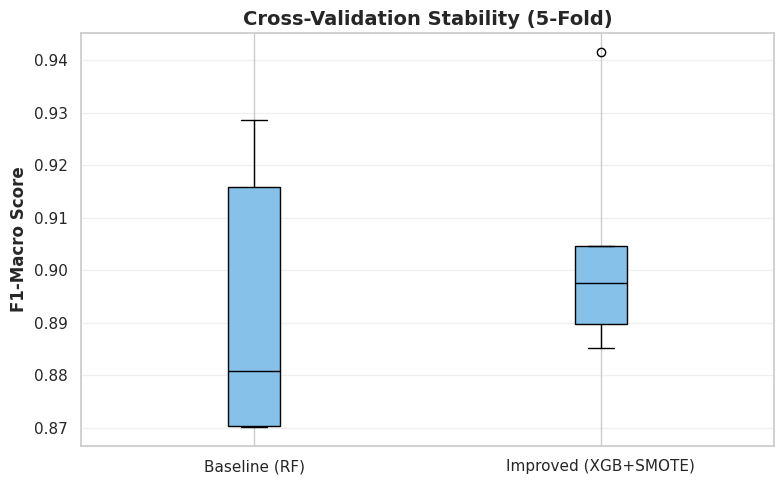

In [44]:
# Cell 15: Stratified K-Fold Cross-Validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

print("Running 5-Fold Stratified Cross-Validation (this may take a minute)...")

# Define CV strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Baseline CV (Random Forest)
rf_cv_scores = cross_val_score(rf_model, X_train_sel, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

# 2. Improved CV (XGBoost + SMOTE)
# Note: SMOTE must be applied inside the CV loop to prevent data leakage.
# We use imblearn's Pipeline to handle this correctly.
from imblearn.pipeline import Pipeline as ImbPipeline
xgb_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=5,
                          objective='multi:softmax', num_class=3,
                          random_state=42, eval_metric='mlogloss'))
])
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train_sel, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

# Print results
print("\n" + "="*60)
print("      5-FOLD CROSS-VALIDATION RESULTS (F1-Macro)")
print("="*60)
print(f"Baseline (Random Forest):       {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})")
print(f"Improved (XGBoost + SMOTE):     {xgb_cv_scores.mean():.4f} (+/- {xgb_cv_scores.std():.4f})")
print("="*60)

# Visualize CV scores
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([rf_cv_scores, xgb_cv_scores], labels=['Baseline (RF)', 'Improved (XGB+SMOTE)'], patch_artist=True,
           boxprops=dict(facecolor='#85c1e9'), medianprops=dict(color='black'))
ax.set_ylabel('F1-Macro Score', fontsize=12, fontweight='bold')
ax.set_title('Cross-Validation Stability (5-Fold)', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

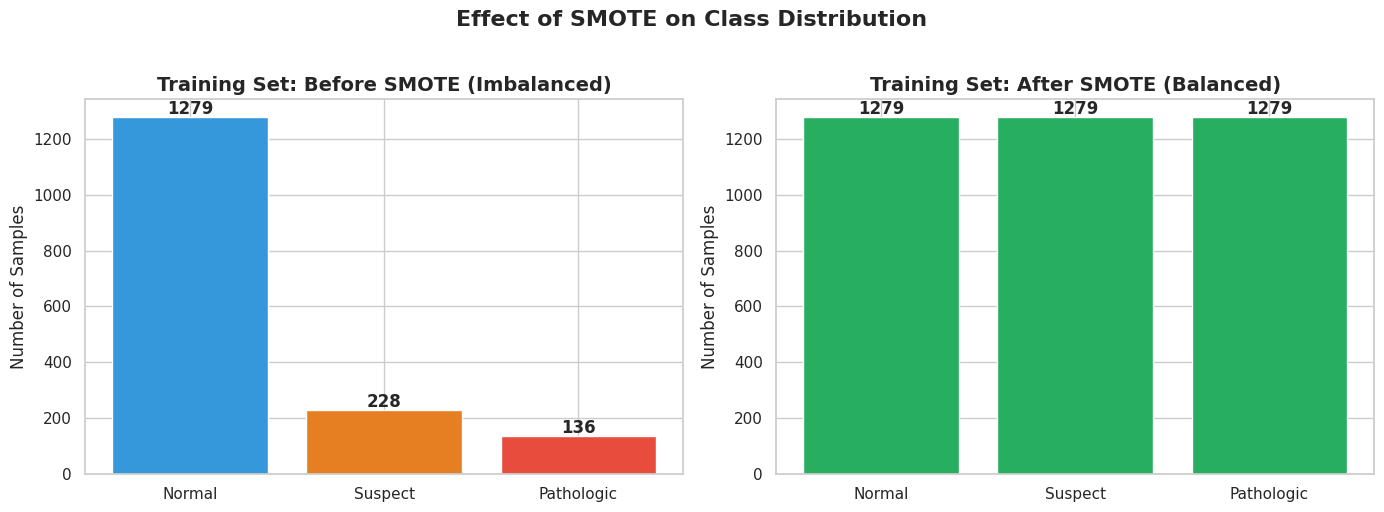

In [41]:
# Visualizing Class Distribution (Pre vs Post SMOTE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before SMOTE
before_counts = pd.Series(y_train).value_counts().sort_index()
axes[0].bar(['Normal', 'Suspect', 'Pathologic'], before_counts.values, color=['#3498db', '#e67e22', '#e74c3c'])
axes[0].set_title('Training Set: Before SMOTE (Imbalanced)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Samples', fontsize=12)
for i, v in enumerate(before_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# After SMOTE
after_counts = pd.Series(y_train_smote).value_counts().sort_index()
axes[1].bar(['Normal', 'Suspect', 'Pathologic'], after_counts.values, color=['#27ae60', '#27ae60', '#27ae60'])
axes[1].set_title('Training Set: After SMOTE (Balanced)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Samples', fontsize=12)
for i, v in enumerate(after_counts.values):
    axes[1].text(i, v + 10, str(v), ha='center', fontweight='bold')

plt.suptitle('Effect of SMOTE on Class Distribution', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

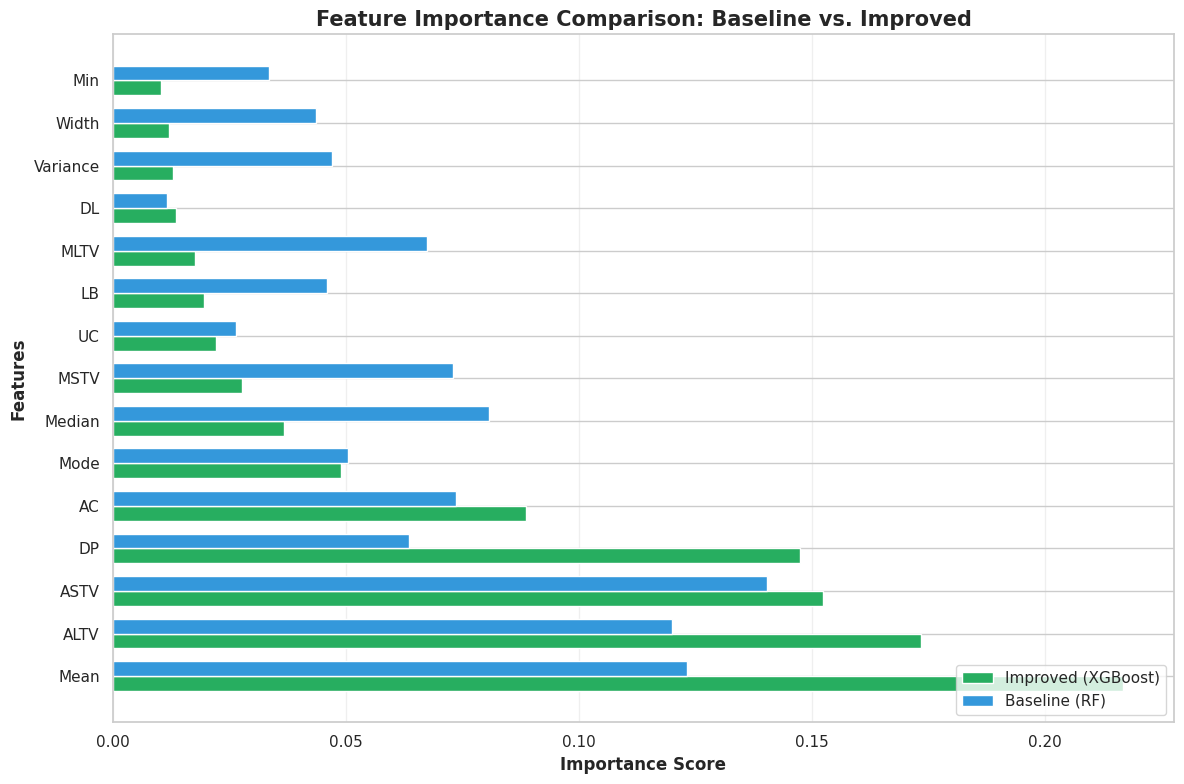


Top 5 Most Important Features (Improved Model):
  Mean: 0.2169
  ALTV: 0.1735
  ASTV: 0.1525
  DP: 0.1474
  AC: 0.0885


In [42]:
# Cell 13: Feature Importance Analysis
# Get the names of the selected features
feature_names = X.columns[selector.get_support()]

# Get feature importances from XGBoost
xgb_importances = xgb_model.feature_importances_
rf_importances = rf_model.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'XGBoost Importance': xgb_importances,
    'Random Forest Importance': rf_importances
}).sort_values('XGBoost Importance', ascending=False)

# Plot top 15 features
fig, ax = plt.subplots(figsize=(12, 8))
x = np.arange(len(importance_df))
width = 0.35

rects1 = ax.barh(x - width/2, importance_df['XGBoost Importance'], width, label='Improved (XGBoost)', color='#27ae60')
rects2 = ax.barh(x + width/2, importance_df['Random Forest Importance'], width, label='Baseline (RF)', color='#3498db')

ax.set_ylabel('Features', fontsize=12, fontweight='bold')
ax.set_xlabel('Importance Score', fontsize=12, fontweight='bold')
ax.set_title('Feature Importance Comparison: Baseline vs. Improved', fontsize=15, fontweight='bold')
ax.set_yticks(x)
ax.set_yticklabels(importance_df['Feature'], fontsize=11)
ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Print the top 5 features
print("\nTop 5 Most Important Features (Improved Model):")
for i, row in importance_df.head(5).iterrows():
    print(f"  {row['Feature']}: {row['XGBoost Importance']:.4f}")

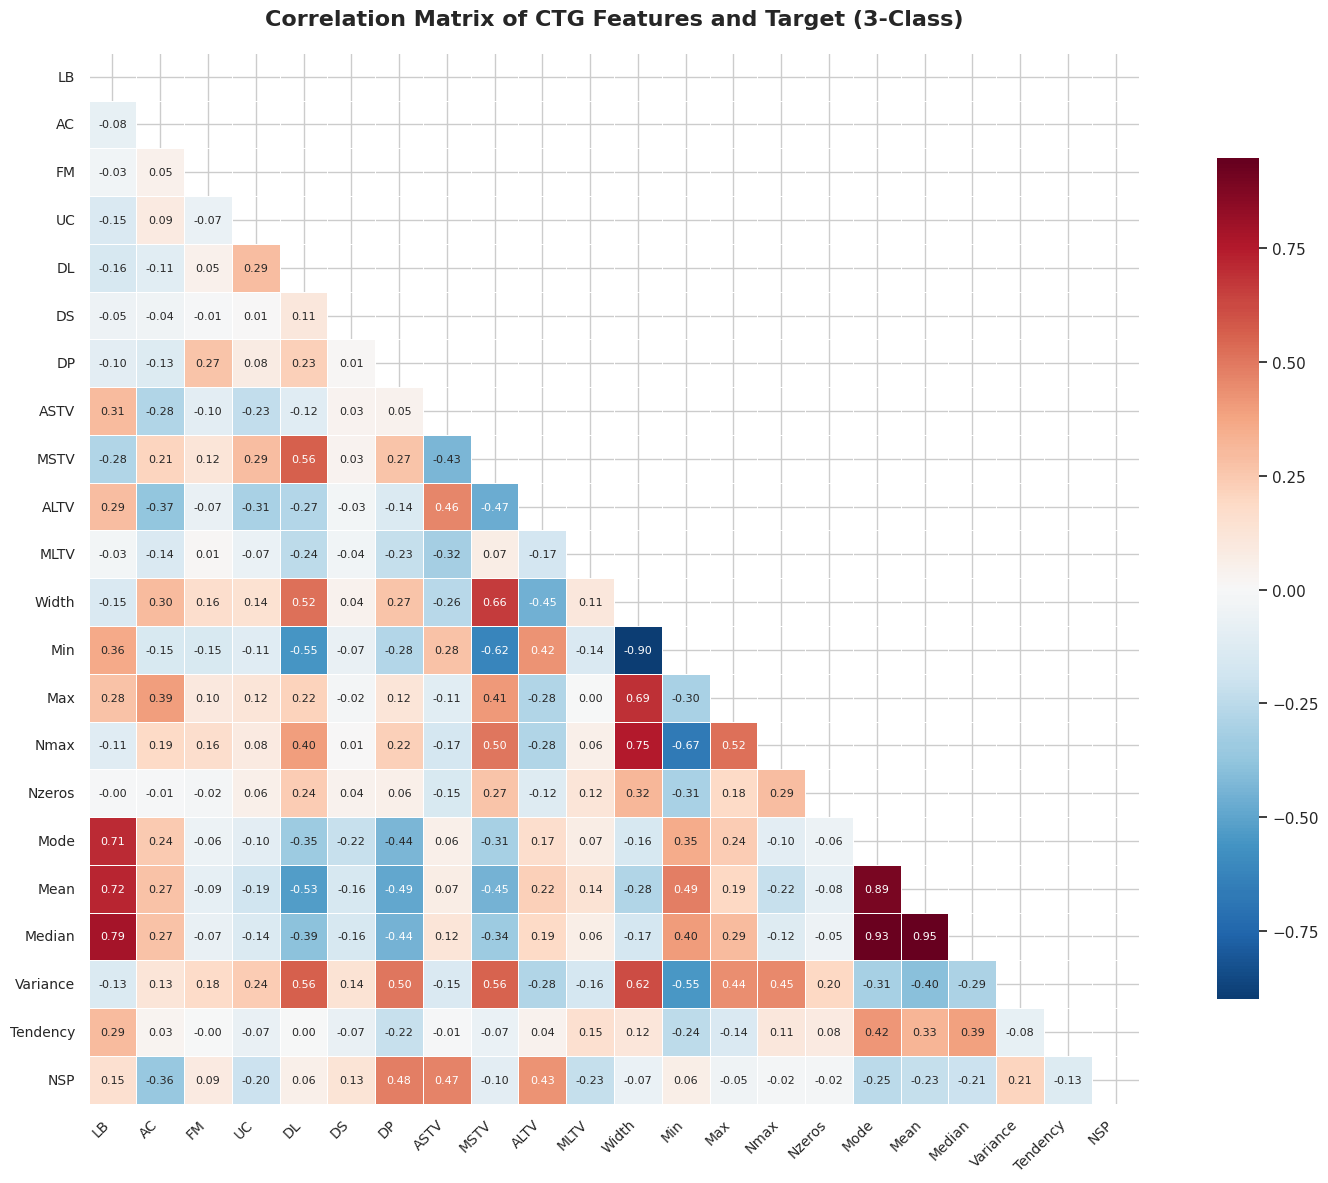

In [32]:
plt.figure(figsize=(16, 12))
df_viz = X.copy()
df_viz['NSP'] = y_multi # 0, 1, 2

corr_matrix = df_viz.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', annot=True, fmt='.2f',
            annot_kws={"size": 8}, center=0, square=True, linewidths=.5,
            cbar_kws={"shrink": 0.8})

plt.title('Correlation Matrix of CTG Features and Target (3-Class)', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

<Figure size 1800x800 with 0 Axes>

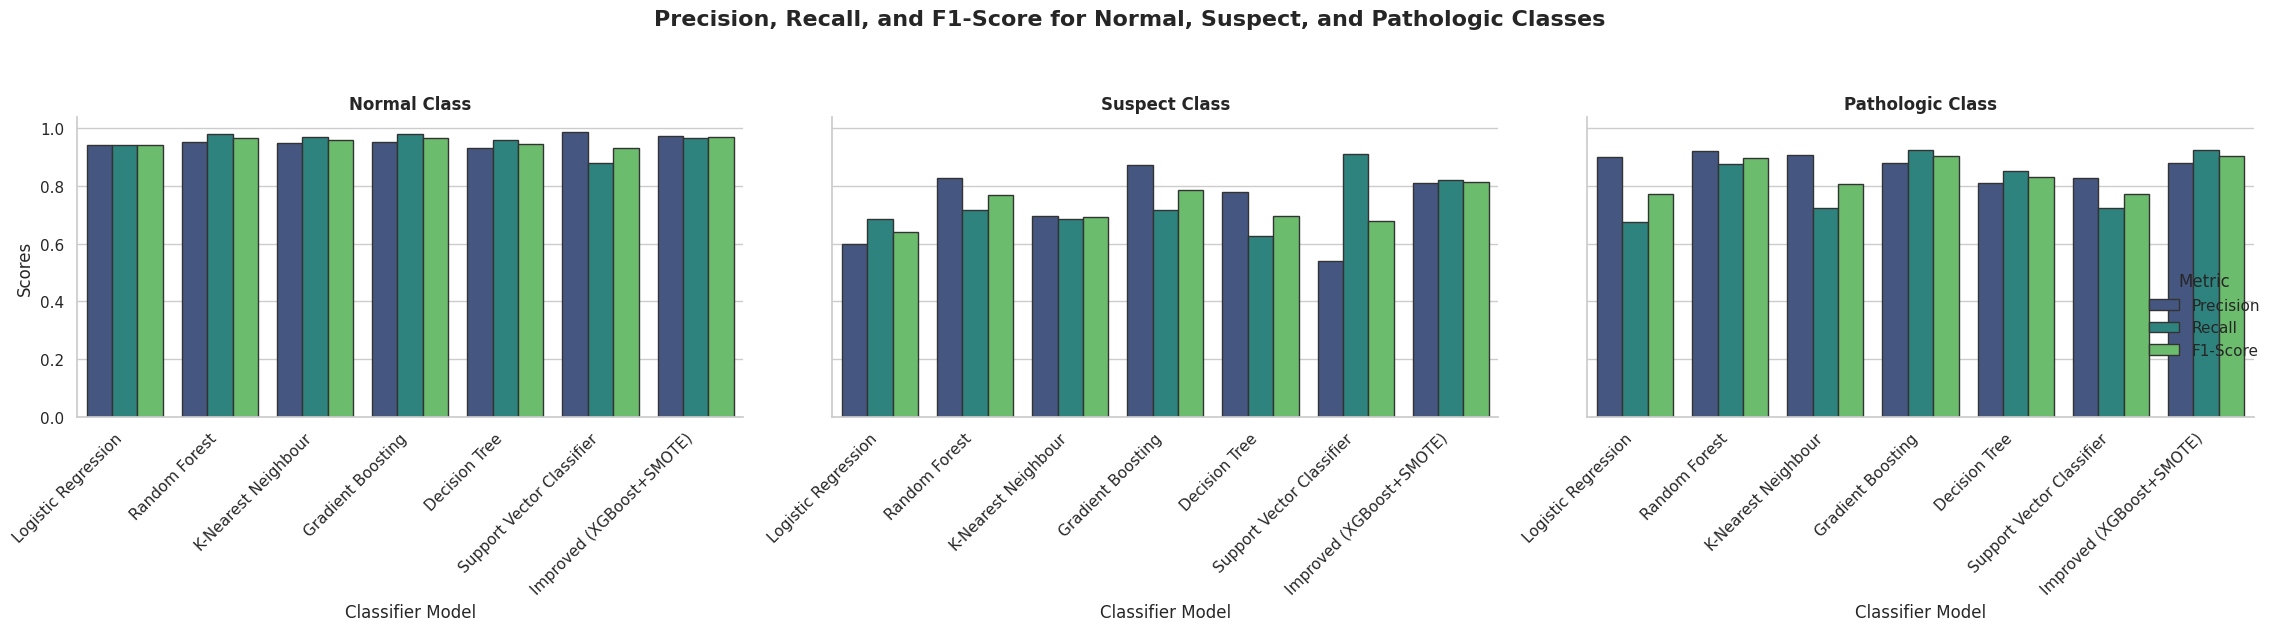

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

# Train all models to collect per-class metrics
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'K-Nearest Neighbour': KNeighborsClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Support Vector Classifier': SVC(random_state=42, class_weight='balanced')
}

results = []

# Baselines
for name, model in models.items():
    model.fit(X_train_sel, y_train)
    y_pred = model.predict(X_test_sel)
    for cls in [0, 1, 2]:
        results.append({
            'Model': name, 'Class': ['Normal', 'Suspect', 'Pathologic'][cls],
            'Precision': precision_score(y_test, y_pred, labels=[cls], average='macro', zero_division=0),
            'Recall': recall_score(y_test, y_pred, labels=[cls], average='macro', zero_division=0),
            'F1-Score': f1_score(y_test, y_pred, labels=[cls], average='macro', zero_division=0)
        })

# Improved Model
for cls in [0, 1, 2]:
    results.append({
        'Model': 'Improved (XGBoost+SMOTE)', 'Class': ['Normal', 'Suspect', 'Pathologic'][cls],
        'Precision': precision_score(y_test, y_pred_xgb, labels=[cls], average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred_xgb, labels=[cls], average='macro', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred_xgb, labels=[cls], average='macro', zero_division=0)
    })

df_results = pd.DataFrame(results)
df_melted = df_results.melt(id_vars=['Model', 'Class'],
                            value_vars=['Precision', 'Recall', 'F1-Score'],
                            var_name='Metric', value_name='Score')

# Plot Grouped Bar Chart
plt.figure(figsize=(18, 8))
sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=df_melted, kind="bar",
    x="Model", y="Score", hue="Metric", col="Class",
    palette="viridis", height=6, aspect=1.2, edgecolor=".2"
)

g.fig.suptitle('Precision, Recall, and F1-Score for Normal, Suspect, and Pathologic Classes',
               fontsize=16, fontweight='bold', y=1.05)
g.set_axis_labels("Classifier Model", "Scores", fontsize=12)
g.set_xticklabels(rotation=45, ha='right', fontsize=11)
g.set_titles("{col_name} Class", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_437/435419766.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_acc, x='Model', y='Accuracy', palette=colors)


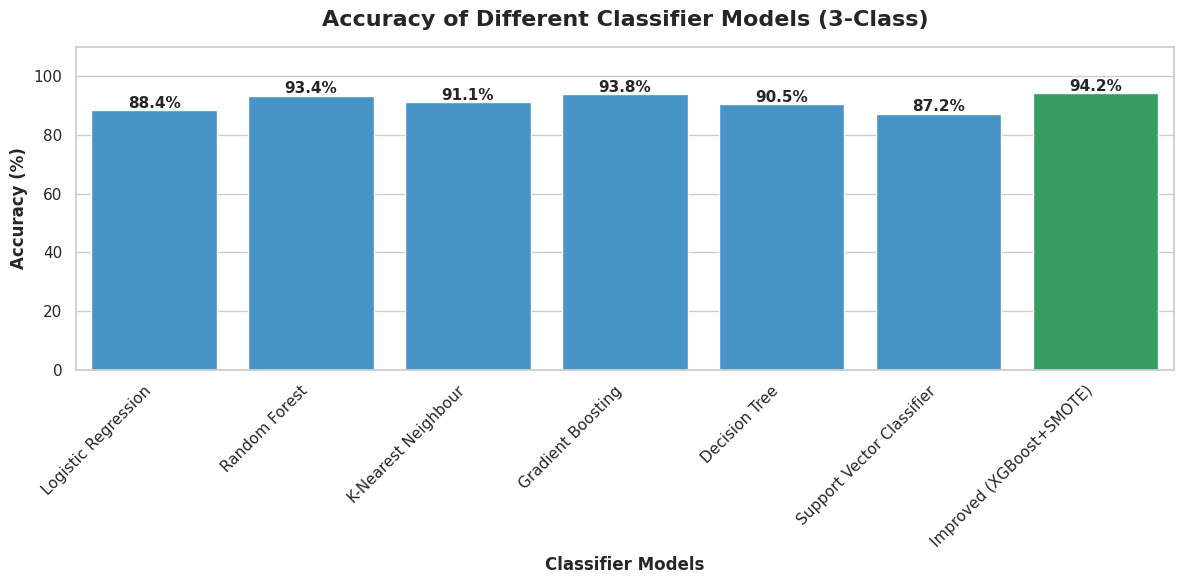

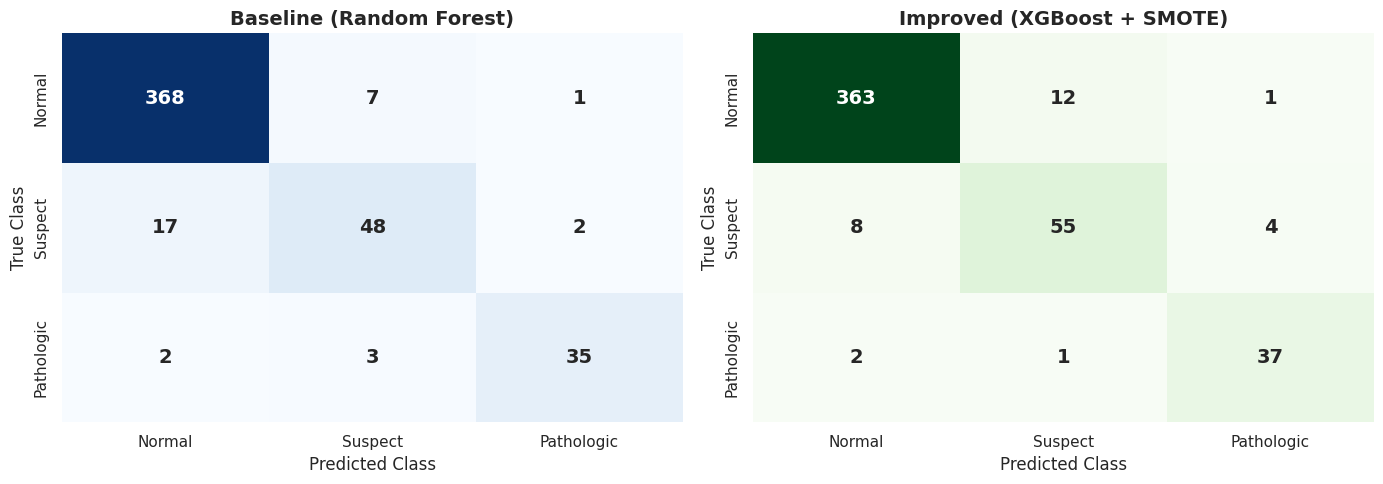

In [35]:
# --- ACCURACY BAR CHART ---
accuracy_results = []
for name, model in models.items():
    y_pred = model.predict(X_test_sel)
    accuracy_results.append({'Model': name, 'Accuracy': accuracy_score(y_test, y_pred) * 100})

accuracy_results.append({'Model': 'Improved (XGBoost+SMOTE)', 'Accuracy': accuracy_score(y_test, y_pred_xgb) * 100})
df_acc = pd.DataFrame(accuracy_results)

plt.figure(figsize=(12, 6))
colors = ['#3498db'] * (len(df_acc) - 1) + ['#27ae60']
ax = sns.barplot(data=df_acc, x='Model', y='Accuracy', palette=colors)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.title('Accuracy of Different Classifier Models (3-Class)', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
plt.xlabel('Classifier Models', fontsize=12, fontweight='bold')
plt.ylim(0, 110)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.tight_layout()
plt.show()

# --- CONFUSION MATRICES ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = ['Normal', 'Suspect', 'Pathologic']

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            annot_kws={"size": 14, "weight": "bold"}, cbar=False,
            xticklabels=labels, yticklabels=labels)
axes[0].set_title('Baseline (Random Forest)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Class', fontsize=12)
axes[0].set_xlabel('Predicted Class', fontsize=12)

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            annot_kws={"size": 14, "weight": "bold"}, cbar=False,
            xticklabels=labels, yticklabels=labels)
axes[1].set_title('Improved (XGBoost + SMOTE)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Class', fontsize=12)
axes[1].set_xlabel('Predicted Class', fontsize=12)

plt.tight_layout()
plt.show()

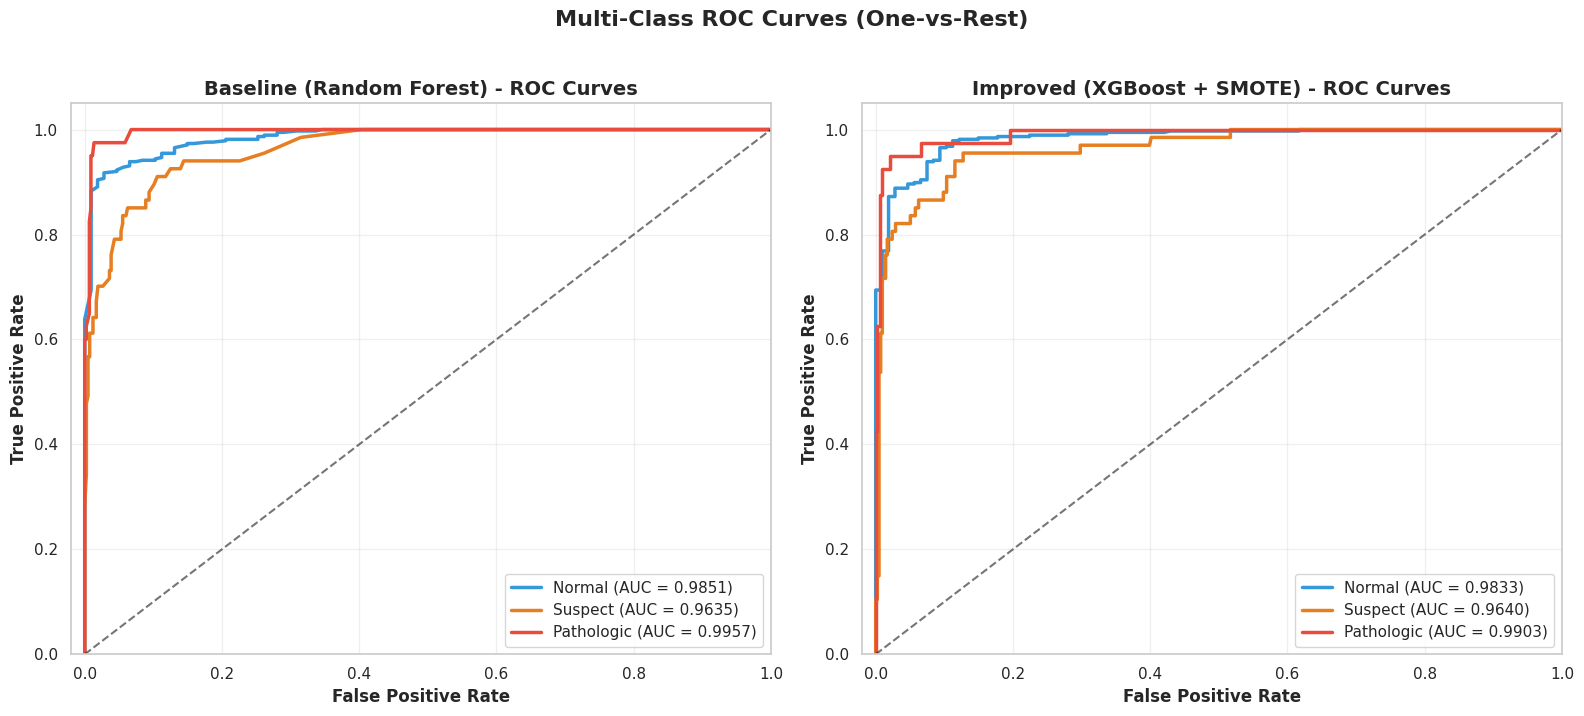

In [36]:
from sklearn.preprocessing import label_binarize
from itertools import cycle

# Binarize the output for ROC curves
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = 3
class_names = ['Normal', 'Suspect', 'Pathologic']
colors = cycle(['#3498db', '#e67e22', '#e74c3c'])

# ==========================================
# ROC CURVES: Baseline vs Improved
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Baseline Random Forest ---
ax = axes[0]
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_probs_rf[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2.5,
            label=f'{class_names[i]} (AUC = {roc_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6)
ax.set_xlim([-0.02, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax.set_title('Baseline (Random Forest) - ROC Curves', fontsize=14, fontweight='bold')
ax.legend(loc="lower right", fontsize=11)
ax.grid(alpha=0.3)

# --- Improved XGBoost + SMOTE ---
ax = axes[1]
colors = cycle(['#3498db', '#e67e22', '#e74c3c'])
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_probs_xgb[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2.5,
            label=f'{class_names[i]} (AUC = {roc_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6)
ax.set_xlim([-0.02, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax.set_title('Improved (XGBoost + SMOTE) - ROC Curves', fontsize=14, fontweight='bold')
ax.legend(loc="lower right", fontsize=11)
ax.grid(alpha=0.3)

plt.suptitle('Multi-Class ROC Curves (One-vs-Rest)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

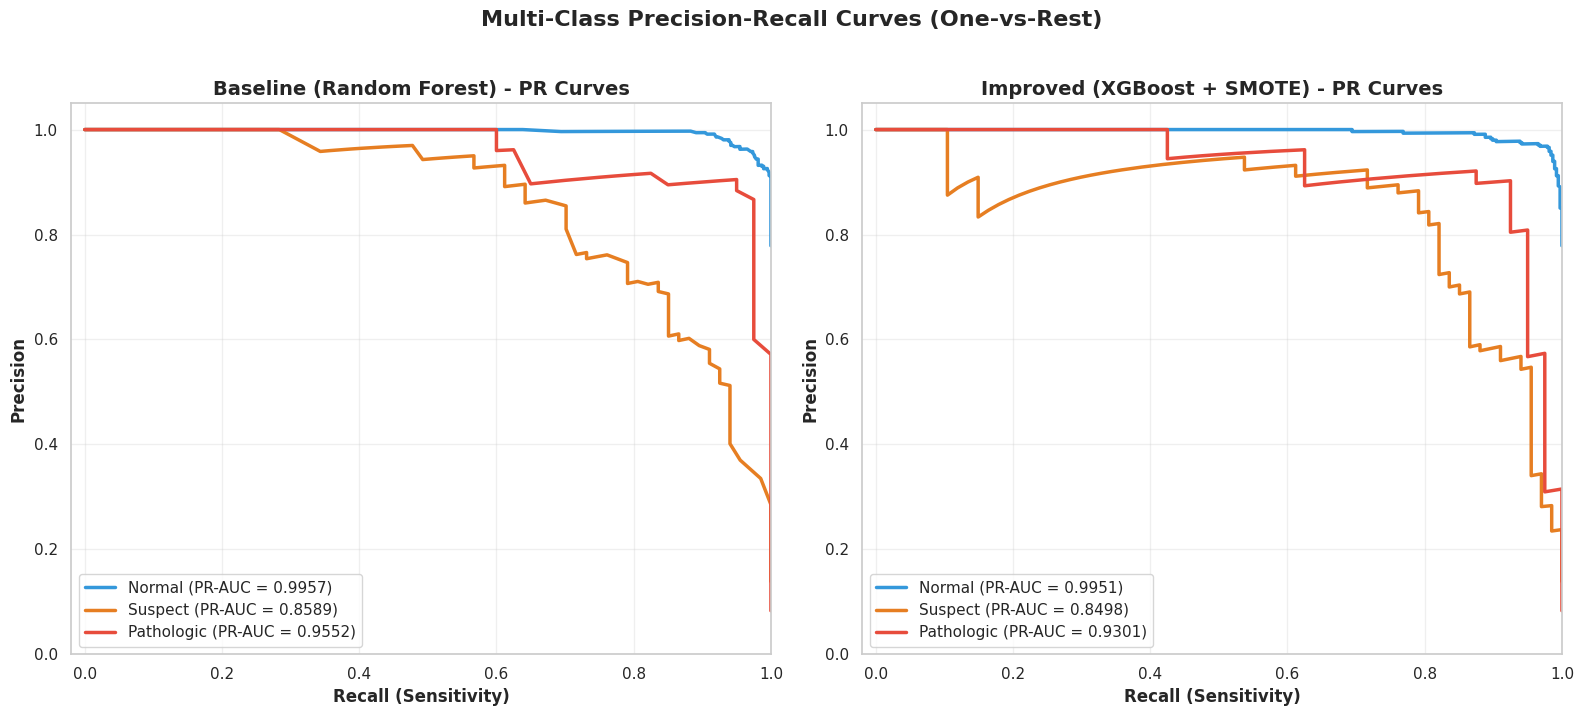

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Baseline Random Forest ---
ax = axes[0]
colors = cycle(['#3498db', '#e67e22', '#e74c3c'])
for i, color in zip(range(n_classes), colors):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_probs_rf[:, i])
    pr_auc = auc(recall, precision)
    ax.plot(recall, precision, color=color, lw=2.5,
            label=f'{class_names[i]} (PR-AUC = {pr_auc:.4f})')

ax.set_xlim([-0.02, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Recall (Sensitivity)', fontsize=12, fontweight='bold')
ax.set_ylabel('Precision', fontsize=12, fontweight='bold')
ax.set_title('Baseline (Random Forest) - PR Curves', fontsize=14, fontweight='bold')
ax.legend(loc="lower left", fontsize=11)
ax.grid(alpha=0.3)

# --- Improved XGBoost + SMOTE ---
ax = axes[1]
colors = cycle(['#3498db', '#e67e22', '#e74c3c'])
for i, color in zip(range(n_classes), colors):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_probs_xgb[:, i])
    pr_auc = auc(recall, precision)
    ax.plot(recall, precision, color=color, lw=2.5,
            label=f'{class_names[i]} (PR-AUC = {pr_auc:.4f})')

ax.set_xlim([-0.02, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Recall (Sensitivity)', fontsize=12, fontweight='bold')
ax.set_ylabel('Precision', fontsize=12, fontweight='bold')
ax.set_title('Improved (XGBoost + SMOTE) - PR Curves', fontsize=14, fontweight='bold')
ax.legend(loc="lower left", fontsize=11)
ax.grid(alpha=0.3)

plt.suptitle('Multi-Class Precision-Recall Curves (One-vs-Rest)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

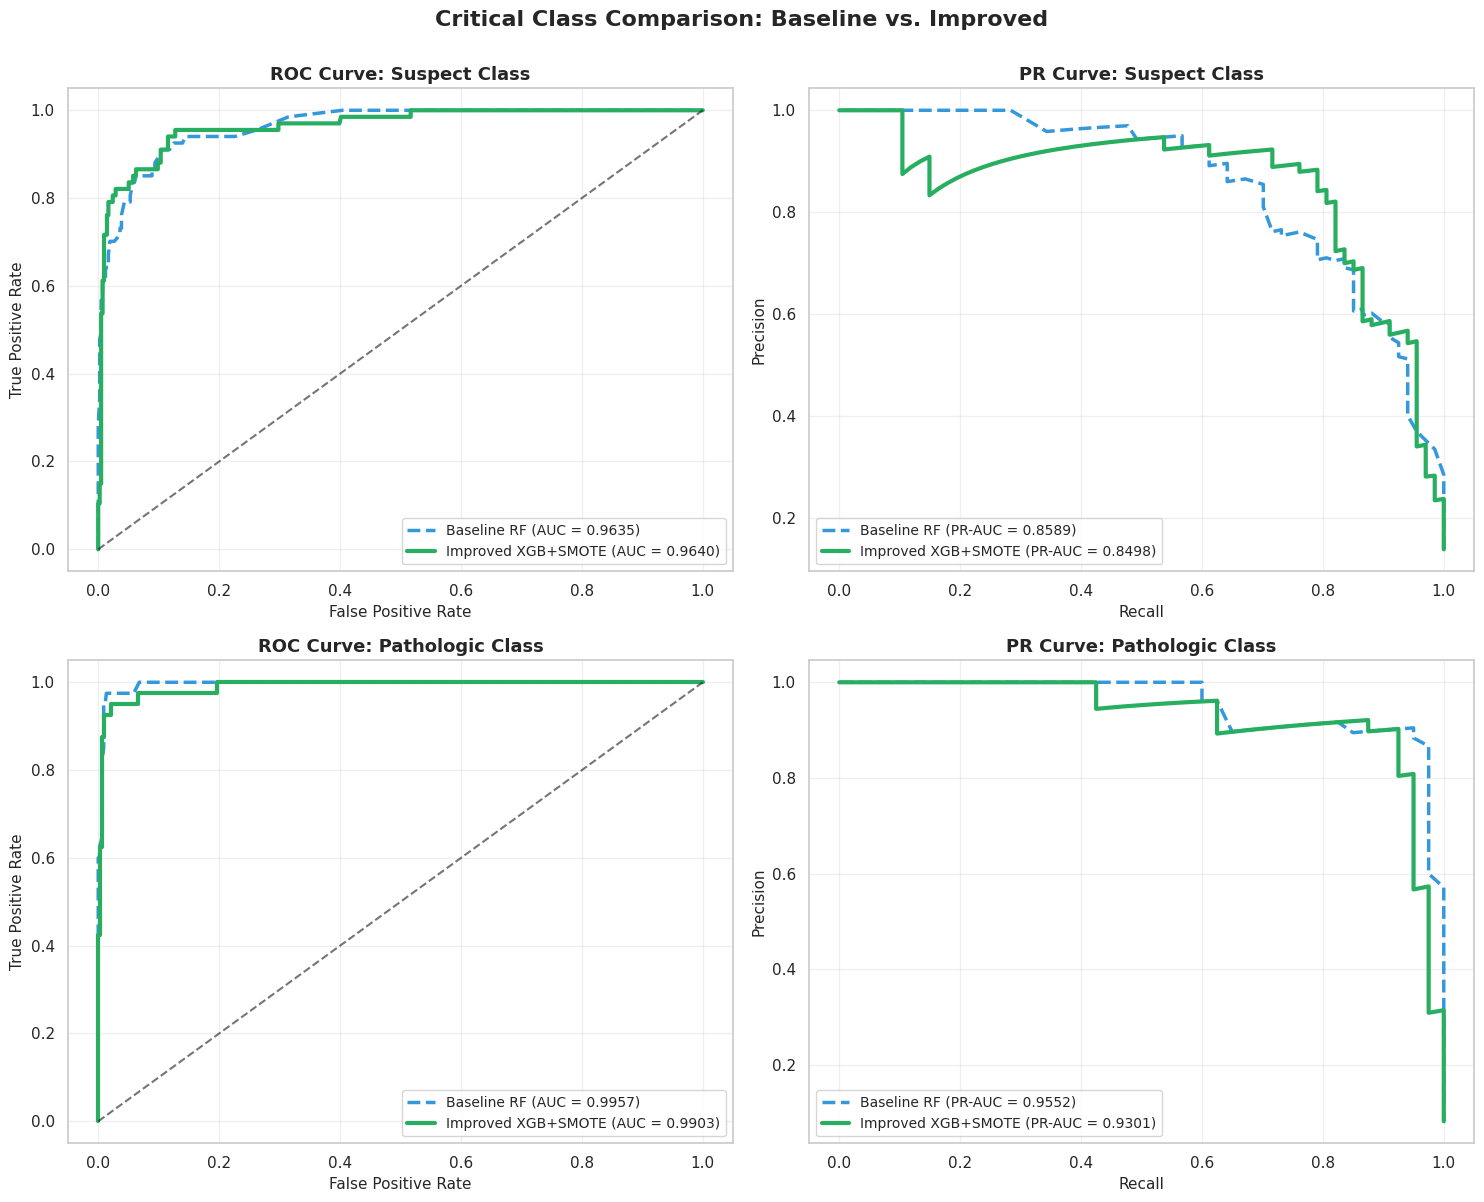

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# --- Row 1: Suspect Class (Class 1) ---
# ROC Curve for Suspect
ax = axes[0, 0]
fpr_rf, tpr_rf, _ = roc_curve(y_test_bin[:, 1], y_probs_rf[:, 1])
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_bin[:, 1], y_probs_xgb[:, 1])
ax.plot(fpr_rf, tpr_rf, color='#3498db', lw=2.5, linestyle='--',
        label=f'Baseline RF (AUC = {auc(fpr_rf, tpr_rf):.4f})')
ax.plot(fpr_xgb, tpr_xgb, color='#27ae60', lw=3,
        label=f'Improved XGB+SMOTE (AUC = {auc(fpr_xgb, tpr_xgb):.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6)
ax.set_title('ROC Curve: Suspect Class', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)

# PR Curve for Suspect
ax = axes[0, 1]
p_rf, r_rf, _ = precision_recall_curve(y_test_bin[:, 1], y_probs_rf[:, 1])
p_xgb, r_xgb, _ = precision_recall_curve(y_test_bin[:, 1], y_probs_xgb[:, 1])
ax.plot(r_rf, p_rf, color='#3498db', lw=2.5, linestyle='--',
        label=f'Baseline RF (PR-AUC = {auc(r_rf, p_rf):.4f})')
ax.plot(r_xgb, p_xgb, color='#27ae60', lw=3,
        label=f'Improved XGB+SMOTE (PR-AUC = {auc(r_xgb, p_xgb):.4f})')
ax.set_title('PR Curve: Suspect Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Recall', fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.legend(loc="lower left", fontsize=10)
ax.grid(alpha=0.3)

# --- Row 2: Pathologic Class (Class 2) ---
# ROC Curve for Pathologic
ax = axes[1, 0]
fpr_rf, tpr_rf, _ = roc_curve(y_test_bin[:, 2], y_probs_rf[:, 2])
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_bin[:, 2], y_probs_xgb[:, 2])
ax.plot(fpr_rf, tpr_rf, color='#3498db', lw=2.5, linestyle='--',
        label=f'Baseline RF (AUC = {auc(fpr_rf, tpr_rf):.4f})')
ax.plot(fpr_xgb, tpr_xgb, color='#27ae60', lw=3,
        label=f'Improved XGB+SMOTE (AUC = {auc(fpr_xgb, tpr_xgb):.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6)
ax.set_title('ROC Curve: Pathologic Class', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)

# PR Curve for Pathologic
ax = axes[1, 1]
p_rf, r_rf, _ = precision_recall_curve(y_test_bin[:, 2], y_probs_rf[:, 2])
p_xgb, r_xgb, _ = precision_recall_curve(y_test_bin[:, 2], y_probs_xgb[:, 2])
ax.plot(r_rf, p_rf, color='#3498db', lw=2.5, linestyle='--',
        label=f'Baseline RF (PR-AUC = {auc(r_rf, p_rf):.4f})')
ax.plot(r_xgb, p_xgb, color='#27ae60', lw=3,
        label=f'Improved XGB+SMOTE (PR-AUC = {auc(r_xgb, p_xgb):.4f})')
ax.set_title('PR Curve: Pathologic Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Recall', fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.legend(loc="lower left", fontsize=10)
ax.grid(alpha=0.3)

plt.suptitle('Critical Class Comparison: Baseline vs. Improved', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

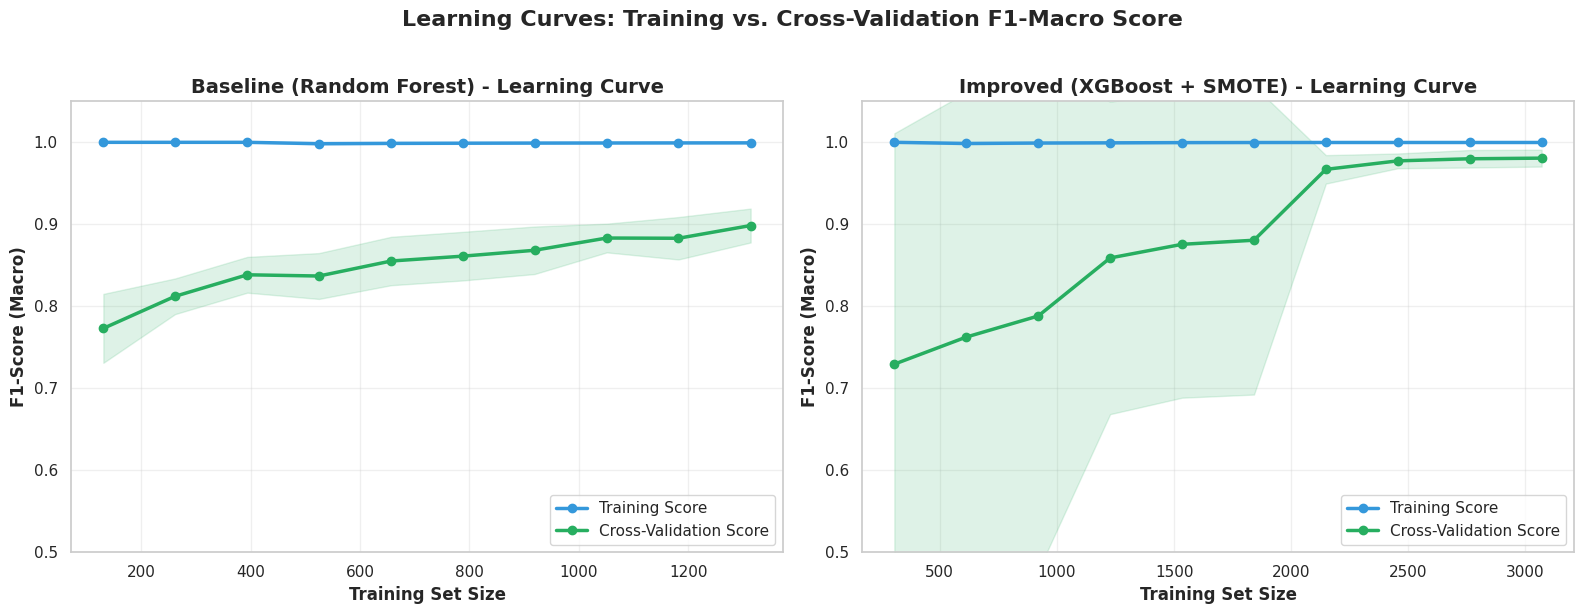

In [39]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

def plot_learning_curve(estimator, title, X, y, ax, cv=5, n_jobs=-1):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='f1_macro', random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    ax.plot(train_sizes, train_mean, 'o-', color='#3498db', lw=2.5, label='Training Score')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#3498db')

    ax.plot(train_sizes, test_mean, 'o-', color='#27ae60', lw=2.5, label='Cross-Validation Score')
    ax.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='#27ae60')

    ax.set_xlabel('Training Set Size', fontsize=12, fontweight='bold')
    ax.set_ylabel('F1-Score (Macro)', fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_ylim([0.5, 1.05])

# Baseline
plot_learning_curve(RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
                    'Baseline (Random Forest) - Learning Curve',
                    X_train_sel, y_train, ax=axes[0])

# Improved
plot_learning_curve(XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=5,
                                   objective='multi:softmax', num_class=3,
                                   random_state=42, eval_metric='mlogloss'),
                    'Improved (XGBoost + SMOTE) - Learning Curve',
                    X_train_smote, y_train_smote, ax=axes[1])

plt.suptitle('Learning Curves: Training vs. Cross-Validation F1-Macro Score',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

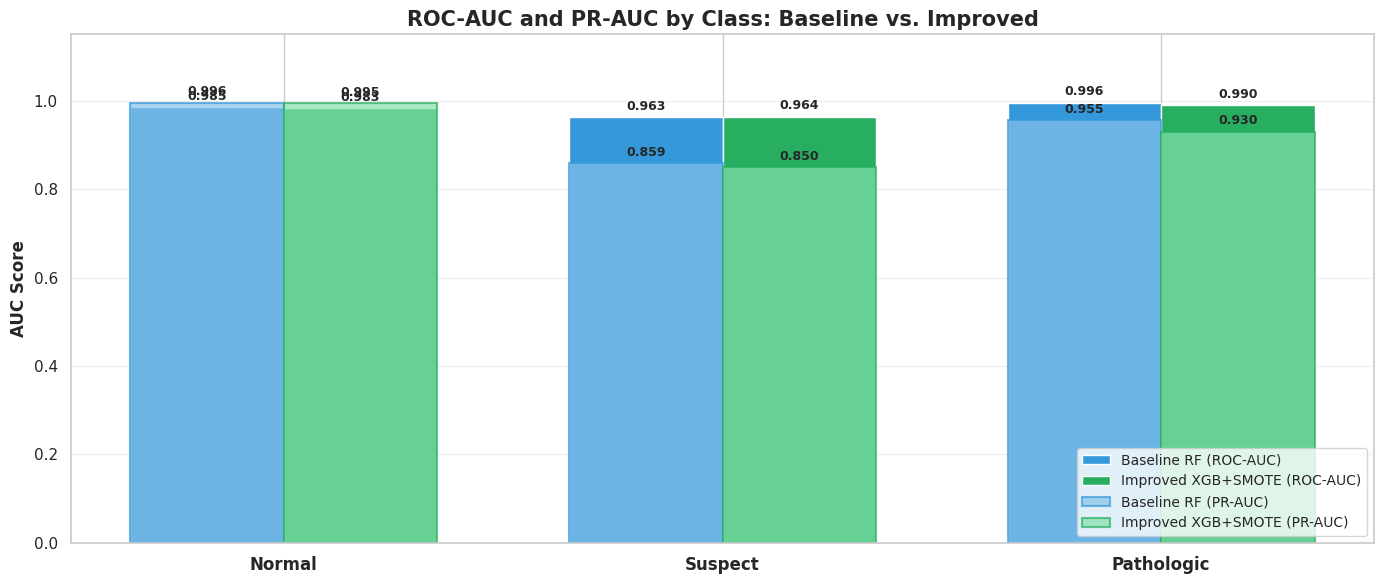


     ROC-AUC AND PR-AUC COMPARISON BY CLASS
Class           Baseline ROC    Improved ROC    Baseline PR     Improved PR    
----------------------------------------------------------------------
Normal          0.9851          0.9833          0.9957          0.9951         
Suspect         0.9635          0.9640          0.8589          0.8498         
Pathologic      0.9957          0.9903          0.9552          0.9301         


In [40]:
# Calculate all AUC scores
roc_aucs_rf, pr_aucs_rf = [], []
roc_aucs_xgb, pr_aucs_xgb = [], []

for i in range(3):
    # Baseline
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_probs_rf[:, i])
    roc_aucs_rf.append(auc(fpr, tpr))
    p, r, _ = precision_recall_curve(y_test_bin[:, i], y_probs_rf[:, i])
    pr_aucs_rf.append(auc(r, p))

    # Improved
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_probs_xgb[:, i])
    roc_aucs_xgb.append(auc(fpr, tpr))
    p, r, _ = precision_recall_curve(y_test_bin[:, i], y_probs_xgb[:, i])
    pr_aucs_xgb.append(auc(r, p))

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(3)
width = 0.35

# ROC-AUC
rects1 = ax.bar(x - width/2, roc_aucs_rf, width, label='Baseline RF (ROC-AUC)', color='#3498db')
rects2 = ax.bar(x + width/2, roc_aucs_xgb, width, label='Improved XGB+SMOTE (ROC-AUC)', color='#27ae60')

# Add PR-AUC as lighter bars
rects3 = ax.bar(x - width/2, pr_aucs_rf, width, label='Baseline RF (PR-AUC)',
                color='#85c1e9', edgecolor='#3498db', linewidth=1.5, alpha=0.7)
rects4 = ax.bar(x + width/2, pr_aucs_xgb, width, label='Improved XGB+SMOTE (PR-AUC)',
                color='#82e0aa', edgecolor='#27ae60', linewidth=1.5, alpha=0.7)

ax.set_ylabel('AUC Score', fontsize=12, fontweight='bold')
ax.set_title('ROC-AUC and PR-AUC by Class: Baseline vs. Improved', fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Normal', 'Suspect', 'Pathologic'], fontsize=12, fontweight='bold')
ax.set_ylim([0, 1.15])
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Annotate values
for rects in [rects1, rects2, rects3, rects4]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary table
print("\n" + "="*70)
print("     ROC-AUC AND PR-AUC COMPARISON BY CLASS")
print("="*70)
print(f"{'Class':<15} {'Baseline ROC':<15} {'Improved ROC':<15} {'Baseline PR':<15} {'Improved PR':<15}")
print("-"*70)
for i, name in enumerate(['Normal', 'Suspect', 'Pathologic']):
    print(f"{name:<15} {roc_aucs_rf[i]:<15.4f} {roc_aucs_xgb[i]:<15.4f} {pr_aucs_rf[i]:<15.4f} {pr_aucs_xgb[i]:<15.4f}")
print("="*70)

In [45]:
# Cell 16: McNemar's Test for Statistical Significance
from statsmodels.stats.contingency_tables import mcnemar

# Create a contingency table
# n00: both wrong, n01: baseline wrong & improved right
# n10: baseline right & improved wrong, n11: both right
both_wrong = np.sum((y_pred_rf != y_test) & (y_pred_xgb != y_test))
baseline_wrong_improved_right = np.sum((y_pred_rf != y_test) & (y_pred_xgb == y_test))
baseline_right_improved_wrong = np.sum((y_pred_rf == y_test) & (y_pred_xgb != y_test))
both_right = np.sum((y_pred_rf == y_test) & (y_pred_xgb == y_test))

table = [[both_right, baseline_right_improved_wrong],
         [baseline_wrong_improved_right, both_wrong]]

# Run McNemar's test
result = mcnemar(table, exact=False, correction=True)

print("="*60)
print("      McNEMAR'S TEST (BASELINE VS IMPROVED)")
print("="*60)
print(f"Contingency Table:\n{table}")
print(f"\nStatistic: {result.statistic:.4f}")
print(f"P-value:   {result.pvalue:.4e}")

if result.pvalue < 0.05:
    print("\n✅ The improvement is STATISTICALLY SIGNIFICANT (p < 0.05).")
else:
    print("\n❌ The improvement is NOT statistically significant (p >= 0.05).")
print("="*60)

      McNEMAR'S TEST (BASELINE VS IMPROVED)
Contingency Table:
[[np.int64(442), np.int64(9)], [np.int64(13), np.int64(19)]]

Statistic: 0.4091
P-value:   5.2243e-01

❌ The improvement is NOT statistically significant (p >= 0.05).
